# IEEE-CIS E-Commerce Fraud Detection & Risk Scoring

## Notebook 01 — Data Audit and Preprocessing

### Objective

This notebook audits the two IEEE-CIS training tables and prepares the data for
chronological fraud modeling.

The main checks cover:

- dataset size and memory use
- key integrity and table relationships
- fraud prevalence
- feature families and data types
- identity-data coverage
- temporal structure
- missingness

The notebook finishes by defining the preprocessing and chronological validation
rules used in the later modeling notebooks.

## 1. Data Ingestion

The IEEE-CIS source files are downloaded directly from Kaggle using the official
CLI. The API token is stored in Colab Secrets and is not written to the notebook
or repository.

Only the labelled training files used in this project are downloaded:

- `train_transaction.csv`
- `train_identity.csv`

The CSV files are read directly from their ZIP archives to avoid unnecessary
extraction and extra runtime storage.

The source competition data are not committed to the repository.

In [1]:
# Install/update the official Kaggle CLI
!pip -q install -U kaggle

In [2]:
from google.colab import userdata
from pathlib import Path
import os
import subprocess
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [3]:
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

In [4]:
REPO_ROOT = Path("/content/ecommerce-fraud-risk-ieee-cis")

FIGURES_DIR = REPO_ROOT / "reports" / "figures"
TABLES_DIR = REPO_ROOT / "reports" / "tables"

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TABLES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

DATA_DIR = Path("/content/data/raw")
DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [5]:
COMPETITION = "ieee-fraud-detection"

files_to_download = [
    "train_transaction.csv",
    "train_identity.csv",
]

for filename in files_to_download:
    subprocess.run(
        [
            "kaggle",
            "competitions",
            "download",
            COMPETITION,
            "-f",
            filename,
            "-p",
            str(DATA_DIR),
        ],
        check=True,
    )

In [6]:
for path in DATA_DIR.iterdir():
    print(f"{path.name:35} {path.stat().st_size / 1024**2:,.1f} MB")

train_transaction.csv.zip           58.3 MB
train_identity.csv.zip              3.3 MB


In [7]:
TRANSACTION_PATH = DATA_DIR / "train_transaction.csv.zip"
IDENTITY_PATH = DATA_DIR / "train_identity.csv.zip"

transactions = pd.read_csv(
    TRANSACTION_PATH,
    compression="zip"
)

identity = pd.read_csv(
    IDENTITY_PATH,
    compression="zip"
)

print(f"Transactions shape: {transactions.shape}")
print(f"Identity shape:     {identity.shape}")

Transactions shape: (590540, 394)
Identity shape:     (144233, 41)


## 2. Structural Audit

Before joining the transaction and identity tables, the dataset structure is
validated to confirm key uniqueness, table relationships, memory footprint,
and identity-data coverage.

In [8]:
def memory_usage_mb(df):
    return df.memory_usage(deep=True).sum() / 1024**2

print(f"Transactions memory: {memory_usage_mb(transactions):,.1f} MB")
print(f"Identity memory:     {memory_usage_mb(identity):,.1f} MB")

Transactions memory: 2,062.1 MB
Identity memory:     143.1 MB


In [9]:
# Preview selected transaction fields

transaction_preview_cols = [
    "TransactionID",
    "isFraud",
    "TransactionDT",
    "TransactionAmt",
    "ProductCD",
    "card1",
    "card2",
    "card4",
    "card6",
    "addr1",
    "dist1",
    "P_emaildomain"
]

display(
    transactions[
        transaction_preview_cols
    ].head(10)
)

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card4,card6,addr1,dist1,P_emaildomain
0,2987000,0,86400,68.500,W,13926,NaN,discover,credit,315.000,19.000,NaN
1,2987001,0,86401,29.000,W,2755,404.000,mastercard,credit,325.000,NaN,gmail.com
2,2987002,0,86469,59.000,W,4663,490.000,visa,debit,330.000,287.000,outlook.com
3,2987003,0,86499,50.000,W,18132,567.000,mastercard,debit,476.000,NaN,yahoo.com
4,2987004,0,86506,50.000,H,4497,514.000,mastercard,credit,420.000,NaN,gmail.com
5,2987005,0,86510,49.000,W,5937,555.000,visa,debit,272.000,36.000,gmail.com
6,2987006,0,86522,159.000,W,12308,360.000,visa,debit,126.000,0.000,yahoo.com
7,2987007,0,86529,422.500,W,12695,490.000,visa,debit,325.000,NaN,mail.com
8,2987008,0,86535,15.000,H,2803,100.000,visa,debit,337.000,NaN,anonymous.com
9,2987009,0,86536,117.000,W,17399,111.000,mastercard,debit,204.000,19.000,yahoo.com


In [10]:
# Preview selected identity fields

identity_preview_cols = [
    "TransactionID",
    "id_01",
    "id_02",
    "id_03",
    "id_05",
    "id_15",
    "id_30",
    "id_31",
    "id_33",
    "id_35",
    "DeviceType",
    "DeviceInfo"
]

display(
    identity[
        identity_preview_cols
    ].head(10)
)

,TransactionID,id_01,id_02,id_03,id_05,id_15,id_30,id_31,id_33,id_35,DeviceType,DeviceInfo
0,2987004,0.000,"70,787.000",NaN,NaN,New,Android 7.0,samsung browser 6.2,2220x1080,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.000,"98,945.000",NaN,0.000,New,iOS 11.1.2,mobile safari 11.0,1334x750,T,mobile,iOS Device
2,2987010,-5.000,"191,631.000",0.000,0.000,Found,NaN,chrome 62.0,NaN,F,desktop,Windows
3,2987011,-5.000,"221,832.000",NaN,0.000,New,NaN,chrome 62.0,NaN,F,desktop,NaN
4,2987016,0.000,"7,460.000",0.000,1.000,Found,Mac OS X 10_11_6,chrome 62.0,1280x800,T,desktop,MacOS
5,2987017,-5.000,"61,141.000",3.000,3.000,Found,Windows 10,chrome 62.0,1366x768,T,desktop,Windows
6,2987022,-15.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2987038,0.000,"31,964.000",0.000,0.000,Found,Android,chrome 62.0,1920x1080,T,mobile,NaN
8,2987040,-10.000,"116,098.000",0.000,0.000,Found,NaN,chrome 62.0,NaN,F,desktop,Windows
9,2987048,-5.000,"257,037.000",NaN,0.000,New,NaN,chrome 62.0,NaN,F,desktop,Windows


In [11]:
# Checks for the uniqueness of TransactionID in tables transactions and identity
# confirms the use of TransactionID as a primary key in these tables

print(
    "TransactionID unique in transactions:",
    transactions["TransactionID"].is_unique
)

print(
    "TransactionID unique in identity:",
    identity["TransactionID"].is_unique
)

# Checks for the duplicates of TransactionID in tables transactions and identity

print(
    "Duplicate TransactionIDs in transactions:",
    transactions["TransactionID"].duplicated().sum()
)

print(
    "Duplicate TransactionIDs in identity:",
    identity["TransactionID"].duplicated().sum()
)

TransactionID unique in transactions: True
TransactionID unique in identity: True
Duplicate TransactionIDs in transactions: 0
Duplicate TransactionIDs in identity: 0


In [12]:
# Checks how many transactions are included in the identity table using TransactionID
# this way we can determine how many transactions come with identity information

identity_coverage = (
    transactions["TransactionID"]
    .isin(identity["TransactionID"])
    .mean()
)

print(
    f"Transactions with identity information: "
    f"{identity_coverage:.2%}"
)

Transactions with identity information: 24.42%


### Structural audit findings

The transaction table uses about **2.06 GB** of memory, compared with about
**143 MB** for the identity table. Memory reduction will therefore be useful
before the tables are merged.

`TransactionID` is unique in both tables, with no duplicated keys.

Only **24.42%** of transactions have a matching identity record. The identity
table is therefore an optional one-to-one extension of the transaction table
rather than a complete second table.

## 3. Target Distribution

Fraud detection is an imbalanced classification problem. Before selecting
evaluation metrics or modeling strategies, the natural class distribution is
quantified without applying any resampling.

In [13]:
# Count legitimate and fraudulent transactions to quantify class imbalance.

target_counts = transactions["isFraud"].value_counts().sort_index()
target_pct = transactions["isFraud"].value_counts(
    normalize=True
).sort_index() * 100

target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_pct
})

target_distribution_table = (
    target_summary
    .rename(
        index={
            0: "Legitimate",
            1: "Fraud"
        }
    )
    .rename_axis(
        "transaction_class"
    )
    .reset_index()
)

display(
    target_distribution_table
)

target_distribution_table.to_csv(
    TABLES_DIR
    / "nb01_target_distribution.csv",
    index=False,
    float_format="%.4f"
)

,transaction_class,count,percentage
0,Legitimate,569877,96.501
1,Fraud,20663,3.499


In [14]:
# Calculates the proportion of fraudulent transactions in the transaction table

fraud_rate = transactions["isFraud"].mean()

# Calculate the legitimate-to-fraud ratio to quantify imbalance severity.

class_ratio = (1 - fraud_rate) / fraud_rate

print(f"Fraud rate: {fraud_rate:.3%}")
print(f"Non-fraud to fraud ratio: {class_ratio:.1f}:1")

Fraud rate: 3.499%
Non-fraud to fraud ratio: 27.6:1


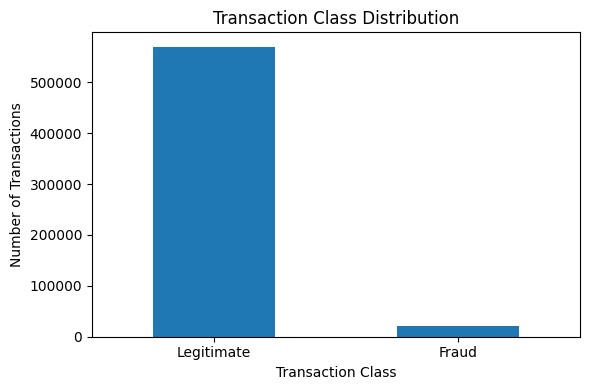

In [15]:
# Visualizes the transaction class distribution using a bar chart

fig, ax = plt.subplots(figsize=(6, 4))

target_counts.plot(
    kind="bar",
    ax=ax
)

ax.set_title("Transaction Class Distribution")
ax.set_xlabel("Transaction Class")
ax.set_ylabel("Number of Transactions")
ax.set_xticklabels(
    ["Legitimate", "Fraud"],
    rotation=0
)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "nb01_transaction_class_distribution.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

## 4. Feature Structure

The dataset contains several groups of transaction, behavioral, payment,
matching, and identity variables. Grouping related variables provides a more
useful structural view than treating hundreds of anonymized columns as an
undifferentiated feature matrix.

In [16]:
# Group related variables by feature family to summarize the high-dimensional
# structure of the dataset. The identity table contains 38 id_* variables,
# plus TransactionID, DeviceType, and DeviceInfo.

feature_groups = {
    "Transaction": [
        c for c in transactions.columns
        if c.startswith("Transaction")
    ],
    "card": [
        c for c in transactions.columns
        if c.startswith("card")
    ],
    "addr": [
        c for c in transactions.columns
        if c.startswith("addr")
    ],
    "dist": [
        c for c in transactions.columns
        if c.startswith("dist")
    ],
    "C": [
        c for c in transactions.columns
        if c.startswith("C") and c[1:].isdigit()
    ],
    "D": [
        c for c in transactions.columns
        if c.startswith("D") and c[1:].isdigit()
    ],
    "M": [
        c for c in transactions.columns
        if c.startswith("M") and c[1:].isdigit()
    ],
    "V": [
        c for c in transactions.columns
        if c.startswith("V") and c[1:].isdigit()
    ],
    "id": [
        c for c in identity.columns
        if c.startswith("id_")
    ],
}

feature_group_summary = pd.DataFrame(
    {
        "feature_group": feature_groups.keys(),
        "n_features": [len(cols) for cols in feature_groups.values()]
    }
)

feature_group_summary

,feature_group,n_features
0,Transaction,3
1,card,6
2,addr,2
3,dist,2
4,C,14
5,D,15
6,M,9
7,V,339
8,id,38


The `V` family contains 339 anonymized variables, while the identity table
contains 38 `id_*` variables.

Their underlying semantics are only partially disclosed, so these groups should
be treated as anonymized feature families rather than assumed to represent direct
identifiers.

Their missingness, stability, and predictive usefulness are examined later in
the workflow.

In [17]:
# Inspect object/categorical columns

transaction_object_cols = (
    transactions
    .select_dtypes(include="object")
    .columns
    .tolist()
)

identity_object_cols = (
    identity
    .select_dtypes(include="object")
    .columns
    .tolist()
)

print(
    f"Transaction object columns: "
    f"{len(transaction_object_cols)}"
)

print(
    f"Identity object columns: "
    f"{len(identity_object_cols)}"
)

Transaction object columns: 14
Identity object columns: 17


In [18]:
# Inspect dtype summary

def dtype_summary(df):
    return (
        df.dtypes
        .astype(str)
        .value_counts()
        .rename_axis("dtype")
        .reset_index(name="n_columns")
    )

print("Transaction dtypes")
display(dtype_summary(transactions))

print("\nIdentity dtypes")
display(dtype_summary(identity))

Transaction dtypes


,dtype,n_columns
0,float64,376
1,object,14
2,int64,4



Identity dtypes


,dtype,n_columns
0,float64,23
1,object,17
2,int64,1


### Initial feature-structure findings

The transaction table is highly dimensional, with 339 anonymized `V` variables
alone. Most transaction variables are loaded as `float64`, which also contributes
substantially to the dataset's approximately 2 GB in-memory footprint.

Categorical information is present in both source tables, with 14 object-type
transaction columns and 17 object-type identity columns. Their cardinality and
missingness will be assessed before an encoding strategy is selected.

## 5. Missingness Overview

Missingness is profiled before any columns are removed or values are imputed.
At this stage the objective is to quantify the scale and distribution of missing
data rather than make preprocessing decisions.

In [19]:
# Determines the missing values count and percentage in the columns of the two tables

def missing_summary(df):
    return (
        pd.DataFrame({
            "missing_count": df.isna().sum(),
            "missing_pct": df.isna().mean() * 100
        })
        .sort_values("missing_pct", ascending=False)
    )


transaction_missing = missing_summary(transactions)
identity_missing = missing_summary(identity)

In [20]:
display(transaction_missing.head(20))

,missing_count,missing_pct
dist2,552913,93.628
D7,551623,93.410
D13,528588,89.509
D14,528353,89.469
D12,525823,89.041
D6,517353,87.607
D9,515614,87.312
D8,515614,87.312
V153,508595,86.124
V149,508595,86.124


In [21]:
display(identity_missing.head(20))

,missing_count,missing_pct
id_24,139486,96.709
id_25,139101,96.442
id_07,139078,96.426
id_08,139078,96.426
id_21,139074,96.423
id_26,139070,96.420
id_23,139064,96.416
id_27,139064,96.416
id_22,139064,96.416
id_18,99120,68.722


Missingness is concentrated in `dist2`, several `D` variables, and large blocks
of `V` variables in the transaction table. In the identity table, the highest
missingness occurs among several `id_*` variables.

`DeviceInfo` is missing for approximately 17.7% of identity rows and is also a
categorical field with potentially high cardinality. Its missing values should
therefore be preserved rather than automatically replaced with the most common
category.

Categorical missingness and unseen future categories are handled explicitly
later using training-derived vocabularies.

In [22]:
# Creates a threshold analysis of missingness in columns of tables Transactions and Identity

thresholds = [
    25,
    50,
    75,
    90
]

missingness_threshold_summary = pd.DataFrame({
    "threshold_pct": thresholds,
    "transaction_columns": [
        int(
            (
                transaction_missing["missing_pct"]
                >= threshold
            ).sum()
        )
        for threshold in thresholds
    ],
    "identity_columns": [
        int(
            (
                identity_missing["missing_pct"]
                >= threshold
            ).sum()
        )
        for threshold in thresholds
    ]
})

display(
    missingness_threshold_summary
)

missingness_threshold_summary.to_csv(
    TABLES_DIR
    / "nb01_missingness_threshold_summary.csv",
    index=False
)

,threshold_pct,transaction_columns,identity_columns
0,25,212,19
1,50,174,12
2,75,168,9
3,90,2,9


In [23]:
# Determines the distribution of missingness in table Transactions

missing_bins = [-0.01, 0, 25, 50, 75, 90, 100]
missing_labels = [
    "0%",
    "0–25%",
    "25–50%",
    "50–75%",
    "75–90%",
    "90–100%"
]

transaction_missing_distribution = (
    pd.cut(
        transaction_missing["missing_pct"],
        bins=missing_bins,
        labels=missing_labels
    )
    .value_counts()
    .sort_index()
)

transaction_missing_distribution

,count
missing_pct,
0%,20
0–25%,162
25–50%,38
50–75%,6
75–90%,166
90–100%,2


### Missingness findings

Missingness is widespread across the dataset.

In the transaction table, **212 columns** have at least 25% missing values,
**174** have at least 50%, and **168** have at least 75%. Only `dist2` and `D7`
exceed 90%.

Identity data have an additional structural issue: only **24.42%** of transactions
have an identity record at all. Even within those records, several `id_*`
variables are more than 96% missing.

This gives two types of missingness:

1. no identity record exists for the transaction;
2. an identity record exists, but individual fields are missing.

No features are removed or imputed at this stage. Later sections test whether
missingness and feature availability are associated with fraud.

## 6. Temporal Structure

`TransactionDT` is not a conventional calendar timestamp. The competition
documentation describes it as a time delta from an undisclosed reference
datetime.

In this project it is therefore treated as elapsed time in seconds. This allows
the dataset to be analyzed in relative days without attempting to infer an actual
calendar date.

The relative time structure is examined to understand the dataset horizon and
to support the later chronological validation strategy.

In [24]:
SECONDS_PER_DAY = 60 * 60 * 24

transaction_day = (
    transactions["TransactionDT"] // SECONDS_PER_DAY
).astype(int)

print(f"First relative day: {transaction_day.min()}")
print(f"Last relative day:  {transaction_day.max()}")
print(f"Observed days:       {transaction_day.nunique()}")

First relative day: 1
Last relative day:  182
Observed days:       182


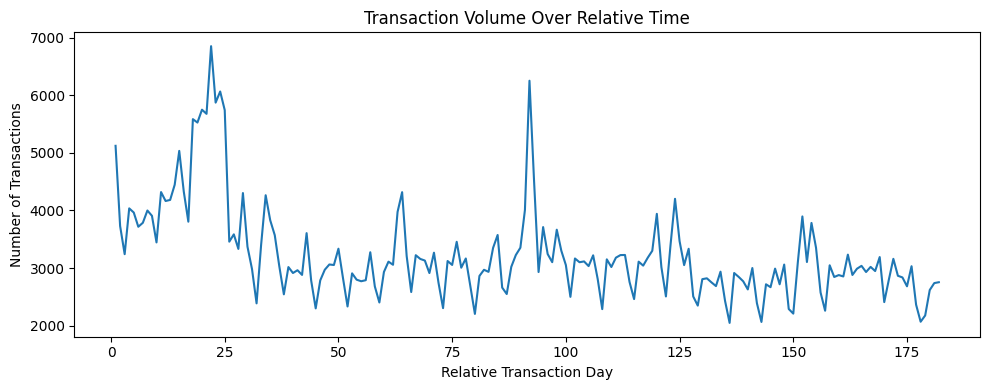

In [25]:
daily_volume = (
    transactions
    .assign(TransactionDay=transaction_day)
    .groupby("TransactionDay")
    .size()
)

fig, ax = plt.subplots(figsize=(10, 4))

daily_volume.plot(ax=ax)

ax.set_title("Transaction Volume Over Relative Time")
ax.set_xlabel("Relative Transaction Day")
ax.set_ylabel("Number of Transactions")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "nb01_transaction_volume_over_time.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

In [26]:
daily_fraud = (
    transactions
    .assign(TransactionDay=transaction_day)
    .groupby("TransactionDay")["isFraud"]
    .agg(
        transactions="count",
        fraud_transactions="sum",
        fraud_rate="mean"
    )
)

daily_fraud.head()

,transactions,fraud_transactions,fraud_rate
TransactionDay,,,
1,5122,112,0.022
2,3730,123,0.033
3,3241,92,0.028
4,4036,115,0.028
5,3964,127,0.032


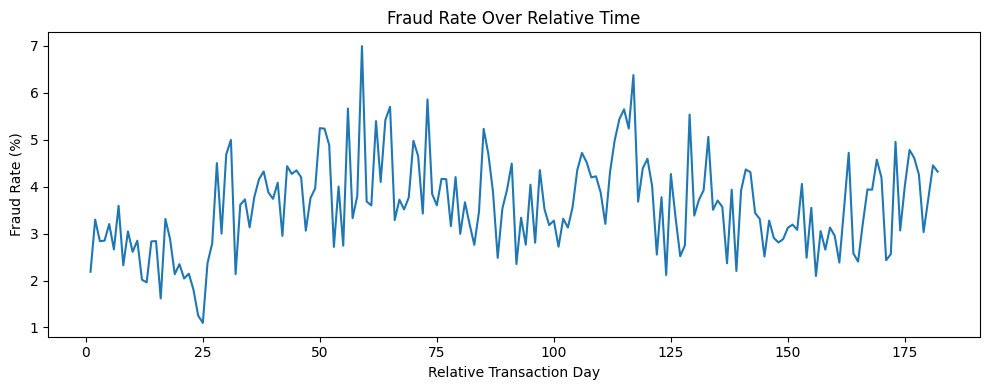

In [27]:
fig, ax = plt.subplots(figsize=(10, 4))

(
    daily_fraud["fraud_rate"] * 100
).plot(ax=ax)

ax.set_title("Fraud Rate Over Relative Time")
ax.set_xlabel("Relative Transaction Day")
ax.set_ylabel("Fraud Rate (%)")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "nb01_fraud_rate_over_time.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

### Temporal audit findings

The training data span **182 relative days**. Both transaction volume and daily
fraud prevalence vary across the period.

This variation matters for validation. A random split would mix earlier and
later transactions, while a chronological split better reflects how the model
would be used on future transactions.

The later evaluation therefore keeps time order intact.

## 7. Numeric Memory Optimization

The raw transaction table occupies approximately 2.06 GB in memory, largely
because pandas loads most numeric features as `float64` and integer variables as
`int64`.

Before joining the transaction and identity tables, numeric columns are
downcast to smaller compatible data types where possible. This reduces memory
usage without changing the number of observations, features, or missing values.

Only numeric storage types are optimized at this stage. Categorical/object
features are deliberately left unchanged because their encoding strategy will
be determined later during preprocessing.

In [28]:
def reduce_numeric_memory(df):
    """
    Downcast numeric columns in-place to reduce memory usage.

    Integer columns are converted to the smallest compatible integer dtype.
    Floating-point columns are converted from float64 to float32 where possible.
    Object/categorical columns are left unchanged.
    """

    start_memory = df.memory_usage(deep=True).sum() / 1024**2

    int_cols = df.select_dtypes(include=["int64"]).columns
    float_cols = df.select_dtypes(include=["float64"]).columns

    for col in int_cols:
        df[col] = pd.to_numeric(
            df[col],
            downcast="integer"
        )

    for col in float_cols:
        df[col] = pd.to_numeric(
            df[col],
            downcast="float"
        )

    end_memory = df.memory_usage(deep=True).sum() / 1024**2

    reduction = 100 * (start_memory - end_memory) / start_memory

    print(f"Memory before: {start_memory:,.1f} MB")
    print(f"Memory after:  {end_memory:,.1f} MB")
    print(f"Reduction:     {reduction:.1f}%")

In [29]:
# Preserve selected original values before numeric downcasting
validation_sample = transactions[
    [
        "TransactionID",
        "TransactionDT",
        "TransactionAmt",
        "isFraud"
    ]
].copy()

In [30]:
print("Transaction table")
reduce_numeric_memory(transactions)

Transaction table
Memory before: 2,062.1 MB
Memory after:  1,203.2 MB
Reduction:     41.7%


In [31]:
print("\nIdentity table")
reduce_numeric_memory(identity)


Identity table
Memory before: 143.1 MB
Memory after:  129.9 MB
Reduction:     9.2%


In [32]:
print(
    "TransactionID preserved:",
    np.array_equal(
        validation_sample["TransactionID"].values,
        transactions["TransactionID"].values
    )
)

print(
    "TransactionDT preserved:",
    np.array_equal(
        validation_sample["TransactionDT"].values,
        transactions["TransactionDT"].values
    )
)

print(
    "Target preserved:",
    np.array_equal(
        validation_sample["isFraud"].values,
        transactions["isFraud"].values
    )
)

print(
    "TransactionAmt numerically consistent:",
    np.allclose(
        validation_sample["TransactionAmt"].values,
        transactions["TransactionAmt"].values,
        equal_nan=True
    )
)

TransactionID preserved: True
TransactionDT preserved: True
Target preserved: True
TransactionAmt numerically consistent: True


In [33]:
del validation_sample
_ = gc.collect()

In [34]:
print("Transaction dtypes after optimization")
display(dtype_summary(transactions))

print("\nIdentity dtypes after optimization")
display(dtype_summary(identity))

Transaction dtypes after optimization


,dtype,n_columns
0,float32,376
1,object,14
2,int32,2
3,int8,1
4,int16,1



Identity dtypes after optimization


,dtype,n_columns
0,float32,23
1,object,17
2,int32,1


In [35]:
transactions.select_dtypes(include=["integer"]).dtypes

,0
TransactionID,int32
isFraud,int8
TransactionDT,int32
card1,int16


In [36]:
identity.select_dtypes(include=["integer"]).dtypes

,0
TransactionID,int32


### Memory optimization result

Numeric downcasting reduced the transaction table from **2,062.1 MB to
1,203.2 MB** (**41.7%**) and the identity table from **143.1 MB to 129.9 MB**
(**9.2%**).

Numeric columns were converted to smaller compatible types, while object columns
were left unchanged.

Checks on `TransactionID`, `TransactionDT`, `isFraud`, and `TransactionAmt`
confirmed that the optimized data remained consistent with the original values.

## 8. Validated Dataset Integration

The transaction and identity tables are joined using `TransactionID`.

A left join is used because the transaction table defines the complete set of
labelled observations, while identity information is available for only a
subset of transactions.

The previously verified uniqueness of `TransactionID` in both tables allows the
join to be explicitly validated as one-to-one. Post-merge integrity checks are
used to confirm that no transaction rows are duplicated or lost.

In [37]:
identity_ids_in_transactions = (
    identity["TransactionID"]
    .isin(transactions["TransactionID"])
    .all()
)

print(
    "All identity records correspond to transactions:",
    identity_ids_in_transactions
)

All identity records correspond to transactions: True


In [38]:
# Record the pre-merge row count

n_transactions_before_merge = len(transactions)

In [39]:
# Define our working dataset that integrates the two tables

df = transactions.merge(
    identity,
    on="TransactionID",
    how="left",
    validate="one_to_one"
)

Using `validate="one_to_one"` makes the expected join relationship explicit.
If the previously verified uniqueness assumption were violated, pandas would
raise an error rather than silently creating duplicated transaction rows.

In [40]:
# Performs the integrity checks on merged shape and memory

print(f"Merged shape: {df.shape}")
print(f"Merged memory: {memory_usage_mb(df):,.1f} MB")

assert len(df) == n_transactions_before_merge
assert df["TransactionID"].is_unique
assert df["isFraud"].isna().sum() == 0

print("Post-merge integrity checks passed.")

Merged shape: (590540, 434)
Merged memory: 1,603.3 MB
Post-merge integrity checks passed.


In [41]:
# Verify that the merge produced the expected number of transactions containing identity data
# first preserve the identity membership in variable `identity_ids` before dropping table `identity`

identity_ids = set(identity["TransactionID"])

In [42]:
merged_identity_coverage = (
    df["TransactionID"].isin(identity_ids).mean()
)

print(
    f"Merged transactions with identity record: "
    f"{merged_identity_coverage:.2%}"
)

Merged transactions with identity record: 24.42%


In [43]:
# Preserve structural identity availability as an explicit indicator

df["has_identity"] = (
    df["TransactionID"]
    .isin(identity_ids)
    .astype("int8")
)

df["has_identity"].value_counts(normalize=True)

,proportion
has_identity,
0,0.756
1,0.244


In [44]:
del transactions
del identity
del identity_ids

_ = gc.collect()

### Dataset integration findings

The two tables were merged with a validated one-to-one left join on
`TransactionID`.

The result contains **590,540 transactions and 434 source columns**. No
transaction rows were duplicated or lost, and the fraud target remained complete.

Identity information is available for **24.42%** of transactions. The
`has_identity` indicator records this structural difference explicitly.

After numeric downcasting and the merge, the working dataset uses about
**1.60 GB** of memory.

In [45]:
df.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Columns: 435 entries, TransactionID to has_identity
dtypes: float32(399), int16(1), int32(2), int8(2), object(31)
memory usage: 1.6 GB


## 9. Missingness and Data Quality Analysis

The initial audit showed that missing information is a major structural
characteristic of the dataset. This section therefore investigates whether
missingness itself is associated with fraud before any broad feature-removal
or imputation strategy is applied.

The analysis begins with structural identity availability, distinguishing
transactions with no identity record from feature-level missing values within
existing identity records.

### 9.1 Structural Identity Missingness

In [46]:
identity_fraud_summary = (
    df.groupby("has_identity")["isFraud"]
    .agg(
        transactions="size",
        fraud_transactions="sum",
        fraud_rate="mean"
    )
)

identity_fraud_summary["fraud_rate_pct"] = (
    identity_fraud_summary["fraud_rate"] * 100
)

identity_fraud_table = (
    identity_fraud_summary[
        [
            "transactions",
            "fraud_transactions",
            "fraud_rate_pct"
        ]
    ]
    .rename(
        index={
            0: "No identity record",
            1: "Identity record"
        }
    )
    .rename_axis(
        "identity_status"
    )
    .reset_index()
)

display(
    identity_fraud_table
)

identity_fraud_table.to_csv(
    TABLES_DIR
    / "nb01_identity_fraud_summary.csv",
    index=False,
    float_format="%.4f"
)

,identity_status,transactions,fraud_transactions,fraud_rate_pct
0,No identity record,446307,9345,2.094
1,Identity record,144233,11318,7.847


In [47]:
fraud_rate_no_identity = identity_fraud_summary.loc[0, "fraud_rate"]
fraud_rate_with_identity = identity_fraud_summary.loc[1, "fraud_rate"]

absolute_difference = (
    fraud_rate_with_identity - fraud_rate_no_identity
)

risk_ratio = (
    fraud_rate_with_identity / fraud_rate_no_identity
)

print(
    f"Fraud rate without identity record: "
    f"{fraud_rate_no_identity:.3%}"
)

print(
    f"Fraud rate with identity record:    "
    f"{fraud_rate_with_identity:.3%}"
)

print(
    f"Absolute difference:                "
    f"{absolute_difference:.3%}"
)

print(
    f"Fraud-rate ratio:                   "
    f"{risk_ratio:.2f}x"
)

Fraud rate without identity record: 2.094%
Fraud rate with identity record:    7.847%
Absolute difference:                5.753%
Fraud-rate ratio:                   3.75x


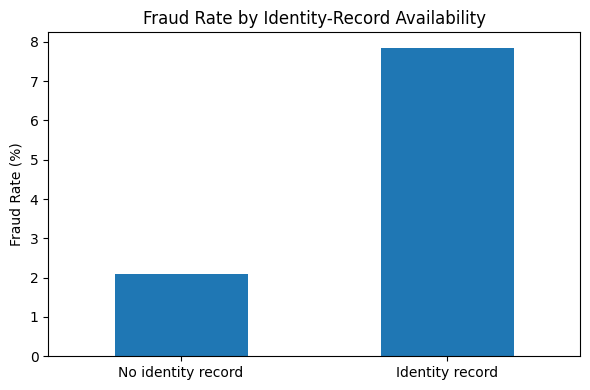

In [48]:
fig, ax = plt.subplots(figsize=(6, 4))

(
    identity_fraud_summary["fraud_rate_pct"]
    .rename(index={
        0: "No identity record",
        1: "Identity record"
    })
    .plot(
        kind="bar",
        ax=ax
    )
)

ax.set_title("Fraud Rate by Identity-Record Availability")
ax.set_xlabel("")
ax.set_ylabel("Fraud Rate (%)")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "nb01_fraud_rate_by_identity_availability.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

In [49]:
identity_by_class = pd.crosstab(
    df["isFraud"],
    df["has_identity"],
    normalize="index"
) * 100

identity_by_class.index = [
    "Legitimate",
    "Fraud"
]

identity_by_class.columns = [
    "No identity record",
    "Identity record"
]

identity_by_class

,No identity record,Identity record
Legitimate,76.677,23.323
Fraud,45.226,54.774


#### Structural Identity Missingness Findings

Identity availability is strongly associated with the fraud target.

Transactions without an identity record have a fraud rate of **2.09%**, compared
with **7.85%** for transactions with identity information — a difference of
**5.75 percentage points** and about **3.75×** in relative terms.

From the opposite direction, **54.77% of fraudulent transactions** have an
identity record, compared with **23.32% of legitimate transactions**.

`has_identity` is therefore retained as a candidate feature. This is an
association, not evidence that identity availability causes fraud.

### 9.2 Row-Level Missingness

Column-level missingness describes how incomplete individual features are, but
transactions may also differ substantially in how much information is available
for each observation.

A row-level missingness measure is therefore created to quantify the proportion
of unavailable features for each transaction and investigate whether overall
data completeness is associated with fraud.

In [50]:
# Exclude columns that do not participate

missingness_exclude = [
    "TransactionID",
    "isFraud",
    "has_identity"
]

feature_cols_for_missingness = [
    col for col in df.columns
    if col not in missingness_exclude
]

In [51]:
df["missing_count"] = (
    df[feature_cols_for_missingness]
    .isna()
    .sum(axis=1)
    .astype("int16")
)

df["missing_pct"] = (
    df["missing_count"]
    / len(feature_cols_for_missingness)
    * 100
).astype("float32")

In [52]:
missing_pct_summary = (
    df["missing_pct"]
    .describe(
        percentiles=[
            0.05,
            0.25,
            0.50,
            0.75,
            0.95
        ]
    )
    .to_frame()
    .T
)

missing_pct_summary.index = [
    "missing_pct"
]

missing_pct_summary

,count,mean,std,min,5%,25%,50%,75%,95%,max
missing_pct,"590,540.000",45.283,11.354,5.556,20.833,48.148,48.843,53.009,57.407,78.704


In [53]:
# Compares legitimate and fraudulent transactions

missingness_by_class = (
    df.groupby("isFraud")["missing_pct"]
    .agg(
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max"
    )
)

missingness_by_class.index = [
    "Legitimate",
    "Fraud"
]

missingness_by_class

,mean,median,std,min,max
Legitimate,45.568,48.843,11.145,5.556,78.704
Fraud,37.430,32.176,13.889,8.102,74.306


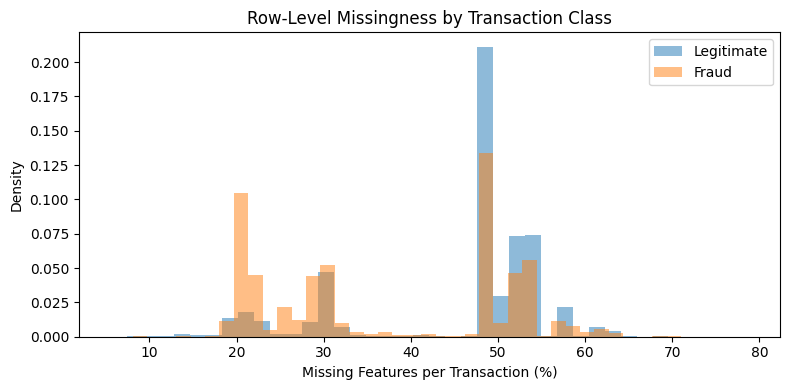

In [54]:
# Plot the histogram of distributions for the two types of transactions

fig, ax = plt.subplots(figsize=(8, 4))

df.loc[df["isFraud"] == 0, "missing_pct"].plot(
    kind="hist",
    bins=40,
    alpha=0.5,
    density=True,
    label="Legitimate",
    ax=ax
)

df.loc[df["isFraud"] == 1, "missing_pct"].plot(
    kind="hist",
    bins=40,
    alpha=0.5,
    density=True,
    label="Fraud",
    ax=ax
)

ax.set_title("Row-Level Missingness by Transaction Class")
ax.set_xlabel("Missing Features per Transaction (%)")
ax.set_ylabel("Density")
ax.legend()

plt.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "nb01_row_missingness_by_class.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

In [55]:
df["missingness_band"] = pd.cut(
    df["missing_pct"],
    bins=[0, 25, 50, 75, 100],
    labels=[
        "0–25%",
        "25–50%",
        "50–75%",
        "75–100%"
    ],
    include_lowest=True
)

In [56]:
missingness_band_summary = (
    df.groupby(
        "missingness_band",
        observed=True
    )["isFraud"]
    .agg(
        transactions="size",
        fraud_transactions="sum",
        fraud_rate="mean"
    )
)

missingness_band_summary["fraud_rate_pct"] = (
    missingness_band_summary["fraud_rate"] * 100
)

missingness_band_table = (
    missingness_band_summary[
        [
            "transactions",
            "fraud_transactions",
            "fraud_rate_pct"
        ]
    ]
    .reset_index()
)

display(
    missingness_band_table
)

missingness_band_table.to_csv(
    TABLES_DIR
    / "nb01_missingness_band_summary.csv",
    index=False,
    float_format="%.4f"
)

,missingness_band,transactions,fraud_transactions,fraud_rate_pct
0,0–25%,58854,5807,9.867
1,25–50%,335728,10209,3.041
2,50–75%,195951,4647,2.372
3,75–100%,7,0,0.000


#### Row-Level Missingness Findings

Fraudulent transactions are more complete on average than legitimate
transactions.

Mean missingness is **37.43%** for fraud and **45.57%** for legitimate
transactions. The median values are **32.18%** and **48.84%**, respectively.

Transactions with **0–25% missing features** have the highest fraud rate at
**9.87%**. Fraud prevalence falls to **3.04%** in the 25–50% band and **2.37%**
in the 50–75% band.

The 75–100% band contains only seven transactions, so its zero fraud count is
not meaningful.

Part of this relationship may be explained by identity availability, which is
examined next.

### 9.3 Missingness Within Identity-Availability Groups

Because identity availability is strongly associated with both data completeness
and fraud prevalence, row-level missingness is examined separately within
transactions with and without identity records.

This helps determine whether missingness provides information beyond the simpler
`has_identity` indicator.

In [57]:
stratified_missingness = (
    df.groupby(
        ["has_identity", "isFraud"]
    )["missing_pct"]
    .agg(
        transactions="size",
        mean_missing_pct="mean",
        median_missing_pct="median"
    )
)

stratified_missingness

transactions  mean_missing_pct  median_missing_pct
has_identity isFraud                                                    
0            0              436962            51.181              49.306
             1                9345            51.401              49.537
1            0              132915            27.114              29.167
             1               11318            25.895              24.074

In [58]:
missingness_identity_summary = (
    df.groupby(
        ["has_identity", "missingness_band"],
        observed=True
    )["isFraud"]
    .agg(
        transactions="size",
        fraud_transactions="sum",
        fraud_rate="mean"
    )
)

missingness_identity_summary["fraud_rate_pct"] = (
    missingness_identity_summary["fraud_rate"] * 100
)

display(
    missingness_identity_summary[
        [
            "transactions",
            "fraud_transactions",
            "fraud_rate_pct"
        ]
    ]
)

transactions  fraud_transactions  \
has_identity missingness_band                                     
0            25–50%                  253447                4899   
             50–75%                  192854                4446   
             75–100%                      6                   0   
1            0–25%                    58854                5807   
             25–50%                   82281                5310   
             50–75%                    3097                 201   
             75–100%                      1                   0   

                               fraud_rate_pct  
has_identity missingness_band                  
0            25–50%                     1.933  
             50–75%                     2.305  
             75–100%                    0.000  
1            0–25%                      9.867  
             25–50%                     6.453  
             50–75%                     6.490  
             75–100%                    0.000

#### Missingness After Accounting for Identity Availability

Identity availability explains much of the overall relationship between
missingness and fraud.

For transactions **without identity data**, mean missingness is almost the same
for legitimate and fraudulent observations: **51.18%** versus **51.40%**.

For transactions **with identity data**, fraud cases remain slightly more
complete: **25.90%** mean missingness versus **27.11%** for legitimate
transactions. Fraud rates are also highest in the most complete 0–25% group.

`has_identity` therefore captures a large part of the missingness pattern, while
`missing_pct` may still add information within transactions that have identity
data. Both are kept as candidate features.

### 9.4 Sparse Feature Usefulness and Removal Candidates

A high missingness rate does not automatically make a feature useless. The
feature may still contain useful values when present, and its availability may
itself carry information.

The highly sparse columns are therefore checked before any missingness-based
removal rule is considered.

These target comparisons are exploratory. They are not used directly to select
features outside the chronological development process.

In [59]:
# Define original candidate features

engineered_cols = [
    "has_identity",
    "missing_count",
    "missing_pct",
    "missingness_band"
]

non_feature_cols = [
    "TransactionID",
    "isFraud"
]

source_feature_cols = [
    col for col in df.columns
    if col not in engineered_cols + non_feature_cols
]

print(f"Original candidate features: {len(source_feature_cols)}")

Original candidate features: 432


In [60]:
# Recalculate sparsity after merging the two tables

merged_missingness = pd.DataFrame({
    "missing_count": df[source_feature_cols].isna().sum(),
    "missing_pct": df[source_feature_cols].isna().mean() * 100
}).sort_values(
    "missing_pct",
    ascending=False
)

merged_missingness.head(20)

,missing_count,missing_pct
id_24,585793,99.196
id_25,585408,99.131
id_07,585385,99.127
id_08,585385,99.127
id_21,585381,99.126
id_26,585377,99.126
id_23,585371,99.125
id_27,585371,99.125
id_22,585371,99.125
dist2,552913,93.628


In [61]:
sparse_cols = merged_missingness[
    merged_missingness["missing_pct"] >= 75
].index.tolist()

extremely_sparse_cols = merged_missingness[
    merged_missingness["missing_pct"] >= 90
].index.tolist()

print(f"Features >= 75% missing: {len(sparse_cols)}")
print(f"Features >= 90% missing: {len(extremely_sparse_cols)}")

Features >= 75% missing: 208
Features >= 90% missing: 12


In [62]:
# Distinguishes the different features in terms of uniqueness of values
# missing percentage and non-null value counts

sparse_feature_audit = pd.DataFrame({
    "missing_pct": merged_missingness.loc[sparse_cols, "missing_pct"],
    "non_null_count": df[sparse_cols].notna().sum(),
    "n_unique_non_null": df[sparse_cols].nunique(dropna=True)
})

sparse_feature_audit = sparse_feature_audit.sort_values(
    ["missing_pct", "non_null_count"],
    ascending=[False, True]
)

sparse_feature_audit.head(20)

,missing_pct,non_null_count,n_unique_non_null
id_24,99.196,4747,12
id_25,99.131,5132,341
id_07,99.127,5155,84
id_08,99.127,5155,94
id_21,99.126,5159,490
id_26,99.126,5163,95
id_23,99.125,5169,3
id_27,99.125,5169,2
id_22,99.125,5169,25
dist2,93.628,37627,1751


In [63]:
# Checks for columns that have no variation
# that means constant or empty columns

constant_or_empty_cols = [
    col for col in source_feature_cols
    if df[col].nunique(dropna=True) <= 1
]

print(
    f"Constant or all-missing source features: "
    f"{len(constant_or_empty_cols)}"
)

constant_or_empty_cols

Constant or all-missing source features: 0


[]

In [64]:
def sparse_presence_signal(df, columns, target="isFraud"):
    results = []

    total_fraud = df[target].sum()
    n_rows = len(df)

    for col in columns:
        present = df[col].notna()

        present_count = int(present.sum())
        missing_count = n_rows - present_count

        present_fraud = int(df.loc[present, target].sum())
        missing_fraud = int(total_fraud - present_fraud)

        present_rate = (
            present_fraud / present_count
            if present_count > 0 else np.nan
        )

        missing_rate = (
            missing_fraud / missing_count
            if missing_count > 0 else np.nan
        )

        results.append({
            "feature": col,
            "missing_pct": missing_count / n_rows * 100,
            "present_count": present_count,
            "fraud_rate_present": present_rate * 100,
            "fraud_rate_missing": missing_rate * 100,
            "absolute_rate_diff_pp":
                abs(present_rate - missing_rate) * 100
        })

    return (
        pd.DataFrame(results)
        .sort_values(
            "absolute_rate_diff_pp",
            ascending=False
        )
        .reset_index(drop=True)
    )

In [65]:
sparse_presence_summary = sparse_presence_signal(
    df,
    sparse_cols
)

sparse_presence_summary.head(20)

,feature,missing_pct,present_count,fraud_rate_present,fraud_rate_missing,absolute_rate_diff_pp
0,D7,93.410,38917,14.878,2.696,12.182
1,D12,89.041,64717,11.740,2.485,9.256
2,D14,89.469,62187,11.599,2.546,9.053
3,D13,89.509,61952,11.036,2.616,8.420
4,id_03,88.769,66324,10.723,2.585,8.138
5,id_04,88.769,66324,10.723,2.585,8.138
6,D6,87.607,73187,10.546,2.502,8.043
7,id_10,87.312,74926,10.446,2.489,7.957
8,D9,87.312,74926,10.446,2.489,7.957
9,D8,87.312,74926,10.446,2.489,7.957


In [66]:
reliable_sparse_presence = (
    sparse_presence_summary[
        sparse_presence_summary["present_count"] >= 1000
    ]
    .copy()
)

reliable_sparse_presence.head(20)

,feature,missing_pct,present_count,fraud_rate_present,fraud_rate_missing,absolute_rate_diff_pp
0,D7,93.410,38917,14.878,2.696,12.182
1,D12,89.041,64717,11.740,2.485,9.256
2,D14,89.469,62187,11.599,2.546,9.053
3,D13,89.509,61952,11.036,2.616,8.420
4,id_03,88.769,66324,10.723,2.585,8.138
5,id_04,88.769,66324,10.723,2.585,8.138
6,D6,87.607,73187,10.546,2.502,8.043
7,id_10,87.312,74926,10.446,2.489,7.957
8,D9,87.312,74926,10.446,2.489,7.957
9,D8,87.312,74926,10.446,2.489,7.957


In [67]:
features_of_interest = [
    "dist2",
    "D7",
    "D13",
    "id_24",
    "id_25",
    "id_07"
]

sparse_presence_examples = (
    sparse_presence_summary[
        sparse_presence_summary[
            "feature"
        ].isin(
            features_of_interest
        )
    ]
    .copy()
)

display(
    sparse_presence_examples
)

sparse_presence_examples.to_csv(
    TABLES_DIR
    / "nb01_sparse_presence_examples.csv",
    index=False,
    float_format="%.4f"
)

,feature,missing_pct,present_count,fraud_rate_present,fraud_rate_missing,absolute_rate_diff_pp
0,D7,93.410,38917,14.878,2.696,12.182
3,D13,89.509,61952,11.036,2.616,8.420
11,dist2,93.628,37627,9.916,3.062,6.853
146,id_24,99.196,4747,8.469,3.459,5.010
147,id_07,99.127,5155,8.264,3.457,4.807
155,id_25,99.131,5132,8.125,3.458,4.667


#### Sparse-Feature Findings

There are **208 source features with at least 75% missingness** and **12 above
90%**, but none of the source variables is completely empty or constant when
observed.

Several sparse features also show large differences in fraud prevalence between
present and missing observations. For example, `D7` is observed for only about
6.6% of transactions, but its fraud rate is **14.88% when present** versus
**2.70% when missing**.

Similar patterns appear for `D13`, `dist2`, and several `id_*` variables.

This does not prove that the observed values themselves are predictive. It does
show that sparse-feature availability can carry information, so features are not
removed simply because they exceed a fixed missingness threshold.

Some features show identical or very similar presence-based fraud statistics,
suggesting shared missingness patterns between related variables. These should
not be interpreted as independent sources of predictive information.

### 9.5 Feature-Retention Policy

The initial modeling dataset follows these rules:

1. **Exclude `TransactionID` from modeling.**  
   It is retained only for traceability. `TransactionDT` remains available as
   the explicit temporal feature.

2. **Keep the source features initially.**  
   No column is removed solely because of a high missingness rate.

3. **Retain `has_identity` and `missing_pct` as candidate features.**  
   Both are deterministic row-level features and do not use the target.
   `missing_count` is kept for analysis only because it contains the same
   information as `missing_pct`.

4. **Use `missingness_band` for analysis only.**  
   The continuous percentage keeps more information for modeling.

5. **Do not apply blanket numeric imputation.**  
   The planned gradient-boosting model can handle missing numeric values
   directly.

6. **Handle categorical missing and unseen values explicitly.**  
   Category vocabularies must be learned from historical training data only.

7. **Keep all target-informed decisions inside the chronological development
   process.**

This keeps the initial feature set broad while leaving later simplification to
temporal validation and model comparison.

In [68]:
# Groups the columns according to the policy above
# and defines identifiers, target, candidate engineered features,
# columns to be excluded and analysis only columns

ID_COL = "TransactionID"
TARGET = "isFraud"

analysis_only_cols = [
    "missing_count",
    "missingness_band"
]

candidate_engineered_features = [
    "has_identity",
    "missing_pct"
]

excluded_model_cols = [
    ID_COL,
    TARGET,
    *analysis_only_cols
]

model_feature_cols = [
    col for col in df.columns
    if col not in excluded_model_cols
]

print(f"Working dataset columns: {df.shape[1]}")
print(f"Candidate model features: {len(model_feature_cols)}")
print(f"Engineered candidate features: {candidate_engineered_features}")

Working dataset columns: 438
Candidate model features: 434
Engineered candidate features: ['has_identity', 'missing_pct']


### Missingness and Data Quality Summary

Missingness in IEEE-CIS is structured rather than random.

Identity availability is strongly associated with fraud, and row-level
completeness also differs between fraud and legitimate transactions. Much of
that relationship is linked to whether an identity record exists.

Sparse variables are not removed solely because of their missingness rate.
Several show informative presence patterns.

The modeling dataset therefore keeps the source features, native missing values,
`has_identity`, and `missing_pct`. Any target-based feature decisions are left
to the chronological development stage.

## 10. Chronological Validation and Leakage-Safe Preprocessing

Fraud prediction is forward-looking, so evaluation should preserve time order.

A random split would mix earlier and later transactions even though transaction
volume, fraud prevalence, and category availability change over time.

The dataset is therefore divided into three chronological blocks:

- development
- post-development calibration and decision work
- final holdout

The development block is split again into model training and internal validation.
Notebook 03 later divides the post-development block into calibration-fit and
threshold-selection periods.

The final holdout is not used for model selection, calibration, or threshold
selection.

### 10.1 Top-Level Chronological Split

In [69]:
SECONDS_PER_DAY = 60 * 60 * 24

relative_day = (
    df["TransactionDT"] // SECONDS_PER_DAY
).astype("int16")

unique_days = np.sort(
    relative_day.unique()
)

n_days = len(unique_days)

DEV_SHARE = 0.70
POST_DEV_SHARE = 0.15

n_dev_days = int(np.floor(n_days * DEV_SHARE))

n_post_dev_days = int(np.floor(n_days * POST_DEV_SHARE))

dev_end_day = int(unique_days[n_dev_days - 1])

post_dev_end_day = int(
    unique_days[n_dev_days + n_post_dev_days - 1]
)

print(f"Observed relative days:   {n_days}")

print(f"Development ends:         day {dev_end_day}")

print(f"Post-development ends:    day {post_dev_end_day}")

print(f"Final holdout begins:     day {post_dev_end_day + 1}")

Observed relative days:   182
Development ends:         day 127
Post-development ends:    day 154
Final holdout begins:     day 155


In [70]:
dev_mask = (
    relative_day <= dev_end_day
)

post_dev_mask = (
    (relative_day > dev_end_day)
    & (relative_day <= post_dev_end_day)
)

holdout_mask = (
    relative_day > post_dev_end_day
)

In [71]:
# Confirm that every observation belongs to exactly one
# chronological period and that the periods do not overlap.

assert (
    dev_mask.astype("int8")
    + post_dev_mask.astype("int8")
    + holdout_mask.astype("int8")
).eq(1).all()

assert (
    df.loc[
        dev_mask,
        "TransactionDT"
    ].max()
    <
    df.loc[
        post_dev_mask,
        "TransactionDT"
    ].min()
)

assert (
    df.loc[
        post_dev_mask,
        "TransactionDT"
    ].max()
    <
    df.loc[
        holdout_mask,
        "TransactionDT"
    ].min()
)

print(
    "Chronological split integrity checks passed."
)

Chronological split integrity checks passed.


### 10.2 Split Audit

In [72]:
def summarize_split(name, mask):
    target = df.loc[mask, TARGET]
    days = relative_day.loc[mask]

    return {
        "period": name,
        "transactions": len(target),
        "row_pct": len(target) / len(df) * 100,
        "fraud_transactions": int(target.sum()),
        "fraud_rate_pct": target.mean() * 100,
        "first_day": int(days.min()),
        "last_day": int(days.max())
    }


split_summary = pd.DataFrame([
    summarize_split(
        "Development",
        dev_mask
    ),
    summarize_split(
        "Post-development",
        post_dev_mask
    ),
    summarize_split(
        "Final holdout",
        holdout_mask
    )
])

display(split_summary)

split_summary.to_csv(
    TABLES_DIR
    / "nb01_top_level_split_summary.csv",
    index=False,
    float_format="%.4f"
)

,period,transactions,row_pct,fraud_transactions,fraud_rate_pct,first_day,last_day
0,Development,437511,74.087,15336,3.505,1,127
1,Post-development,74487,12.613,2553,3.427,128,154
2,Final holdout,78542,13.300,2774,3.532,155,182


In [73]:
# Validates that each period contains at least one fraudulent transaction

assert (
    split_summary["fraud_transactions"] > 0
).all()

print("All evaluation periods contain fraudulent transactions.")

All evaluation periods contain fraudulent transactions.


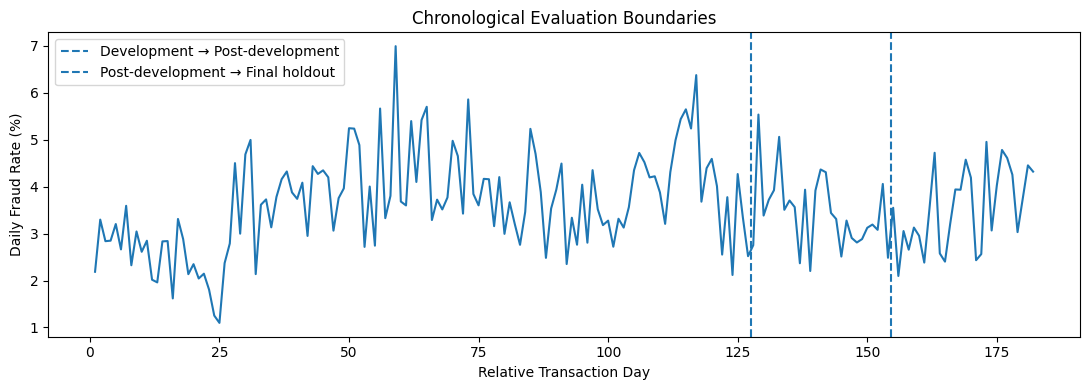

In [74]:
daily_split_audit = (
    df.assign(
        TransactionDay=relative_day
    )
    .groupby("TransactionDay")["isFraud"]
    .agg(
        transactions="size",
        fraud_rate="mean"
    )
)

fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(
    daily_split_audit.index,
    daily_split_audit["fraud_rate"] * 100
)

ax.axvline(
    dev_end_day + 0.5,
    linestyle="--",
    label="Development → Post-development"
)

ax.axvline(
    post_dev_end_day + 0.5,
    linestyle="--",
    label="Post-development → Final holdout"
)

ax.set_title(
    "Chronological Evaluation Boundaries"
)

ax.set_xlabel(
    "Relative Transaction Day"
)

ax.set_ylabel(
    "Daily Fraud Rate (%)"
)

ax.legend()

plt.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "nb01_chronological_evaluation_boundaries.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

### 10.3 Internal model-validation split

In [75]:
development_days = unique_days[
    unique_days <= dev_end_day
]

DEV_TRAIN_SHARE = 0.80

n_dev_train_days = int(
    np.floor(
        len(development_days)
        * DEV_TRAIN_SHARE
    )
)

dev_train_end_day = int(
    development_days[
        n_dev_train_days - 1
    ]
)

dev_train_mask = (
    dev_mask
    & (relative_day <= dev_train_end_day)
)

dev_valid_mask = (
    dev_mask
    & (relative_day > dev_train_end_day)
)

print(
    f"Development training ends: "
    f"day {dev_train_end_day}"
)

print(
    f"Internal validation begins: "
    f"day {dev_train_end_day + 1}"
)

Development training ends: day 101
Internal validation begins: day 102


In [76]:
model_period_summary = pd.DataFrame([
    summarize_split(
        "Model training",
        dev_train_mask
    ),
    summarize_split(
        "Internal validation",
        dev_valid_mask
    ),
    summarize_split(
        "Post-development",
        post_dev_mask
    ),
    summarize_split(
        "Final holdout",
        holdout_mask
    )
])

display(model_period_summary)

model_period_summary.to_csv(
    TABLES_DIR
    / "nb01_model_period_summary.csv",
    index=False,
    float_format="%.4f"
)

,period,transactions,row_pct,fraud_transactions,fraud_rate_pct,first_day,last_day
0,Model training,356216,60.320,12039,3.380,1,101
1,Internal validation,81295,13.766,3297,4.056,102,127
2,Post-development,74487,12.613,2553,3.427,128,154
3,Final holdout,78542,13.300,2774,3.532,155,182


In [77]:
assert (
    df.loc[
        dev_train_mask,
        "TransactionDT"
    ].max()
    <
    df.loc[
        dev_valid_mask,
        "TransactionDT"
    ].min()
)

print(
    "Internal development split "
    "is also chronological."
)

Internal development split is also chronological.


### 10.4 Validation Protocol and Leakage Control

Model development uses the earlier development period for fitting and the later
development period for internal validation and early stopping.

Once the model specification is chosen, it is refitted on the full development
period.

The later post-development block is handled in Notebook 03: its earlier part is
used for probability calibration and its later part for threshold selection.

The final holdout is used only for final system evaluation.

#### Leakage-Control Rule

Any transformation that learns parameters from multiple observations must be
fitted only on its designated historical partition.

This includes category vocabularies, frequency or aggregation statistics,
imputation values, feature-selection rules, and model parameters.

Calibration is fitted later on the calibration-fit period, and threshold
selection uses the subsequent decision period.

Row-level calculations such as `has_identity` and `missing_pct` do not learn
from other observations and can be calculated independently for each period.

### 10.5 Categorical Handling and Temporal Drift

In [78]:
categorical_cols = [
    col
    for col in model_feature_cols
    if df[col].dtype == "object"
]

numeric_cols = [
    col
    for col in model_feature_cols
    if col not in categorical_cols
]

print(
    f"Candidate categorical features: "
    f"{len(categorical_cols)}"
)

print(
    f"Candidate numeric features: "
    f"{len(numeric_cols)}"
)

Candidate categorical features: 31
Candidate numeric features: 403


In [79]:
MISSING_TOKEN = "__MISSING__"
UNSEEN_TOKEN = "__UNSEEN__"


def fit_category_schema(
    train_df,
    categorical_columns
):
    schema = {}

    for col in categorical_columns:

        observed = (
            train_df[col]
            .dropna()
            .astype("string")
            .unique()
        )

        observed = pd.Index(observed)

        if (
            MISSING_TOKEN in observed
            or UNSEEN_TOKEN in observed
        ):
            raise ValueError(
                f"Reserved token already "
                f"exists in {col}"
            )

        schema[col] = observed

    return schema

In [80]:
dev_train_category_schema = (
    fit_category_schema(
        df.loc[
            dev_train_mask
        ],
        categorical_cols
    )
)

In [81]:
def apply_category_schema(
    frame,
    schema
):
    transformed = frame.copy()

    for col, known_categories in schema.items():

        values = (
            transformed[col]
            .astype("string")
        )

        missing_mask = values.isna()

        unseen_mask = (
            ~missing_mask
            & ~values.isin(
                known_categories
            )
        )

        values = values.mask(
            missing_mask,
            MISSING_TOKEN
        )

        values = values.mask(
            unseen_mask,
            UNSEEN_TOKEN
        )

        categories = (
            list(known_categories)
            + [
                MISSING_TOKEN,
                UNSEEN_TOKEN
            ]
        )

        transformed[col] = pd.Categorical(
            values,
            categories=categories
        )

    return transformed

In [82]:
def unseen_category_summary(
    frame,
    schema
):
    results = []

    for col, known_categories in schema.items():

        values = (
            frame[col]
            .astype("string")
        )

        non_missing = values.notna()

        unseen = (
            non_missing
            & ~values.isin(
                known_categories
            )
        )

        non_missing_count = int(
            non_missing.sum()
        )

        unseen_count = int(
            unseen.sum()
        )

        unseen_pct = (
            unseen_count
            / non_missing_count
            * 100
            if non_missing_count > 0
            else 0
        )

        results.append({
            "feature": col,
            "non_missing_count":
                non_missing_count,
            "unseen_count":
                unseen_count,
            "unseen_pct":
                unseen_pct
        })

    return (
        pd.DataFrame(results)
        .sort_values(
            "unseen_pct",
            ascending=False
        )
        .reset_index(drop=True)
    )

In [83]:
dev_valid_unseen = (
    unseen_category_summary(
        df.loc[
            dev_valid_mask
        ],
        dev_train_category_schema
    )
)

display(
    dev_valid_unseen.head(15)
)

dev_valid_unseen.to_csv(
    TABLES_DIR
    / "nb01_unseen_category_summary.csv",
    index=False,
    float_format="%.4f"
)

,feature,non_missing_count,unseen_count,unseen_pct
0,id_31,16003,4923,30.763
1,DeviceInfo,12394,325,2.622
2,id_33,5459,128,2.345
3,P_emaildomain,70360,0,0.000
4,ProductCD,81295,0,0.000
5,card4,81291,0,0.000
6,card6,81291,0,0.000
7,M3,57810,0,0.000
8,M4,46123,0,0.000
9,M5,34529,0,0.000


#### Temporal Categorical Drift

Most categorical variables introduce few or no unseen values during internal
validation.

`id_31` is the main exception: **30.8%** of its non-missing validation values
were not seen during training. Smaller unseen rates occur for `DeviceInfo`
(**2.62%**) and `id_33` (**2.35%**).

Category vocabularies are therefore fitted on historical training data only.
New future values are mapped to `__UNSEEN__`.

The high unseen rate of `id_31` is also worth monitoring as a sign of temporal
category drift.

### 10.6 Numeric missing values

Numeric missing values are deliberately retained at this stage.

The primary gradient-boosting model can handle missing numeric values directly,
which allows potentially informative missingness patterns to remain available to
the model. Blanket mean, median, or sentinel-value imputation is therefore not
applied before establishing whether it improves temporal validation performance.

If a later comparison requires an algorithm that cannot process missing values
natively, any imputation statistics will be fitted using the historical training
period only.

### 10.7 Split Summary

The 182 observed days are divided using fixed chronological boundaries.

Fraud prevalence varies across the periods: it is **3.38%** during model training
and **4.06%** during internal validation. The boundaries are not adjusted to
produce similar fraud rates.

Row proportions also differ from the nominal 70% / 15% / 15% time split because
transaction volume changes from day to day.

The fixed time boundaries are retained for all later modeling and evaluation.

In [84]:
# Record the chronological configuration used across the project.

SPLIT_CONFIG = {
    "model_train": (
        1,
        dev_train_end_day
    ),
    "internal_validation": (
        dev_train_end_day + 1,
        dev_end_day
    ),
    "calibration_and_decision": (
        dev_end_day + 1,
        post_dev_end_day
    ),
    "final_holdout": (
        post_dev_end_day + 1,
        int(unique_days.max())
    )
}

SPLIT_CONFIG

{'model_train': (1, 101),
 'internal_validation': (102, 127),
 'calibration_and_decision': (128, 154),
 'final_holdout': (155, 182)}

### Validation and Preprocessing Summary

The project now has a fixed chronological evaluation protocol:

- days **1–101**: model training
- days **102–127**: internal validation
- days **128–154**: post-development calibration and decision work
- days **155–182**: final holdout

Categorical preprocessing uses historical vocabularies and explicit handling of
future unseen values. Numeric missing values remain native for the
gradient-boosting model.

From this point onward, any learned preprocessing or modeling decision uses only
its designated historical partition.